In [13]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
os.makedirs("../reports/figures", exist_ok=True)   # folder to save graphs

df = pd.read_csv("../data/clean.csv")
date_cols = df.columns[1:-2]          # all columns except CONS_NO, MISSING_PCT, FLAG
usage = df[date_cols].copy()
usage.columns = pd.to_datetime(usage.columns)
flag = df["FLAG"]
names = flag.map({0: "Honest", 1: "Thief"})
print(usage.shape)

(42289, 1034)


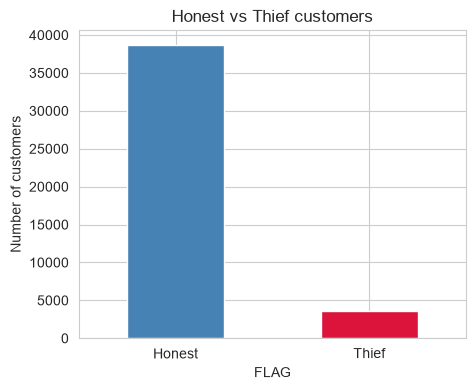

In [14]:
names.value_counts().plot(kind="bar", color=["steelblue", "crimson"], figsize=(5, 4))
plt.title("Honest vs Thief customers")
plt.ylabel("Number of customers")
plt.xticks(rotation=0)
plt.savefig("../reports/figures/1_class_balance.png", dpi=150, bbox_inches="tight")
plt.show()

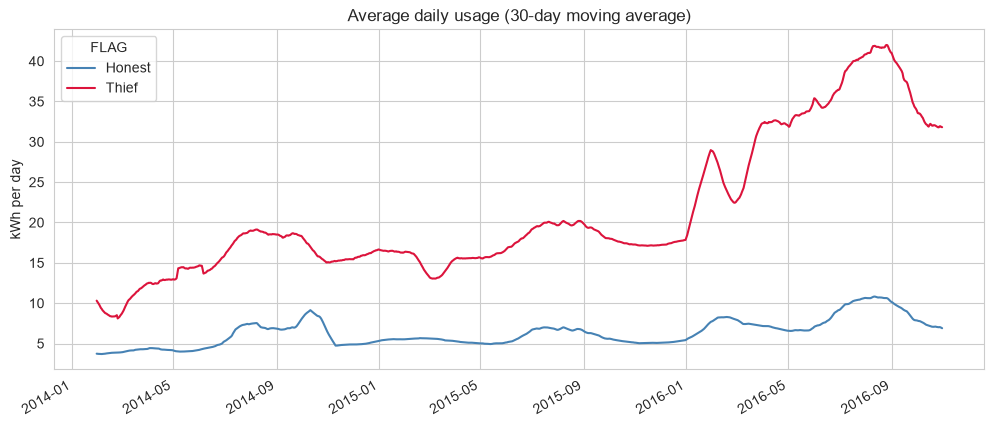

In [15]:
avg = usage.groupby(names).mean().T     # rows = dates, columns = Honest / Thief
avg.rolling(30).mean().plot(figsize=(12, 5), color=["steelblue", "crimson"])
plt.title("Average daily usage (30-day moving average)")
plt.ylabel("kWh per day")
plt.savefig("../reports/figures/2_usage_over_time.png", dpi=150, bbox_inches="tight")
plt.show()

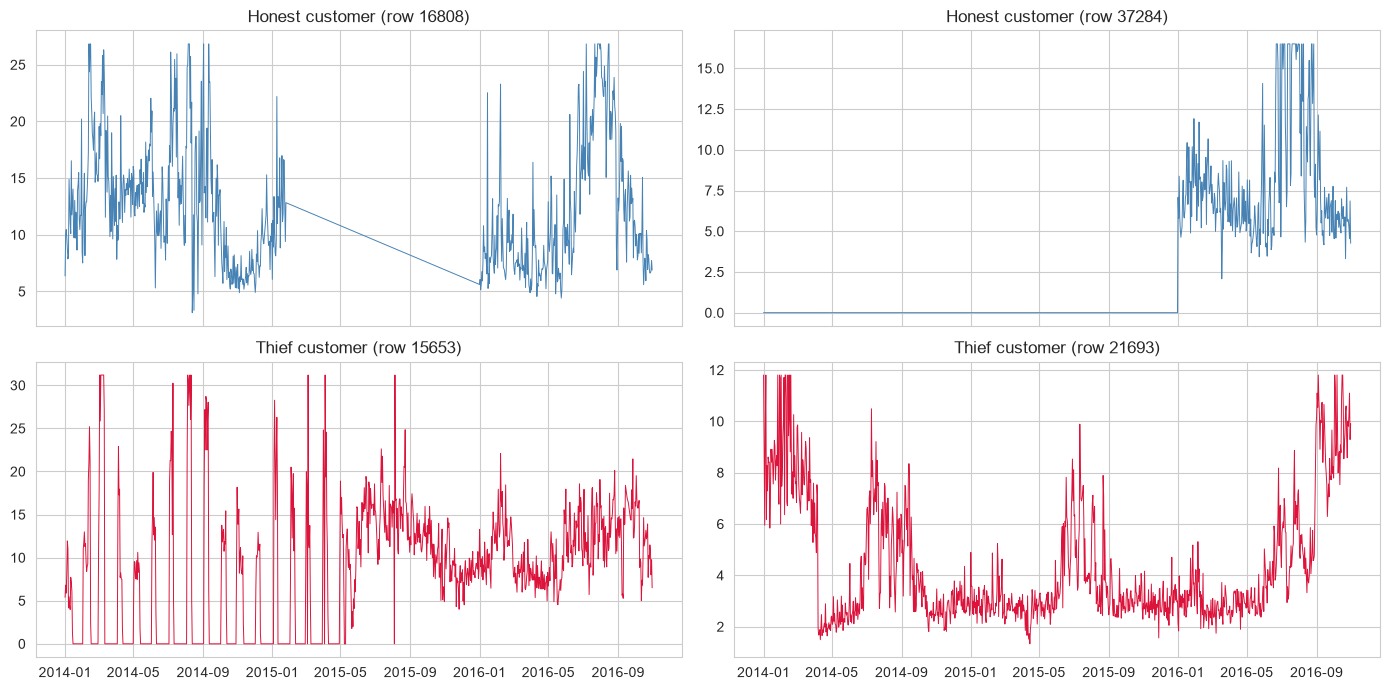

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharex=True)
honest_ids = df[flag == 0].sample(2, random_state=7).index
thief_ids = df[flag == 1].sample(2, random_state=7).index

for ax, i in zip(axes[0], honest_ids):
    ax.plot(usage.columns, usage.loc[i], color="steelblue", linewidth=0.7)
    ax.set_title(f"Honest customer (row {i})")
for ax, i in zip(axes[1], thief_ids):
    ax.plot(usage.columns, usage.loc[i], color="crimson", linewidth=0.7)
    ax.set_title(f"Thief customer (row {i})")

plt.tight_layout()
plt.savefig("../reports/figures/3_sample_customers.png", dpi=150, bbox_inches="tight")
plt.show()

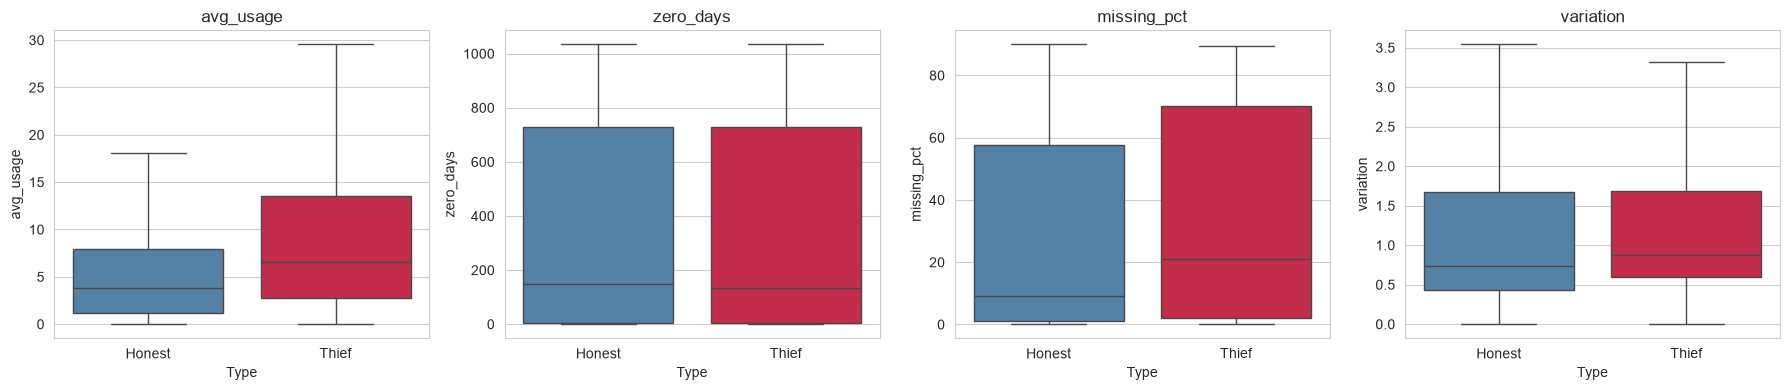

        avg_usage  zero_days  missing_pct  variation
Type                                                
Honest       3.85      150.0         9.19       0.73
Thief        6.59      133.0        21.18       0.88


In [20]:
stats = pd.DataFrame({
    "Type": names,
    "avg_usage": usage.mean(axis=1),
    "zero_days": (usage == 0).sum(axis=1),
    "missing_pct": df["MISSING_PCT"],
    "variation": usage.std(axis=1) / (usage.mean(axis=1) + 1e-6),
})

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, ["avg_usage", "zero_days", "missing_pct", "variation"]):
    sns.boxplot(data=stats, x="Type", y=col, ax=ax, showfliers=False,
                hue="Type", order=["Honest", "Thief"],
                palette={"Honest": "steelblue", "Thief": "crimson"}, legend=False)
    ax.set_title(col)
plt.tight_layout()
plt.savefig("../reports/figures/4_customer_stats.png", dpi=150, bbox_inches="tight")
plt.show()

print(stats.groupby("Type").median().round(2))

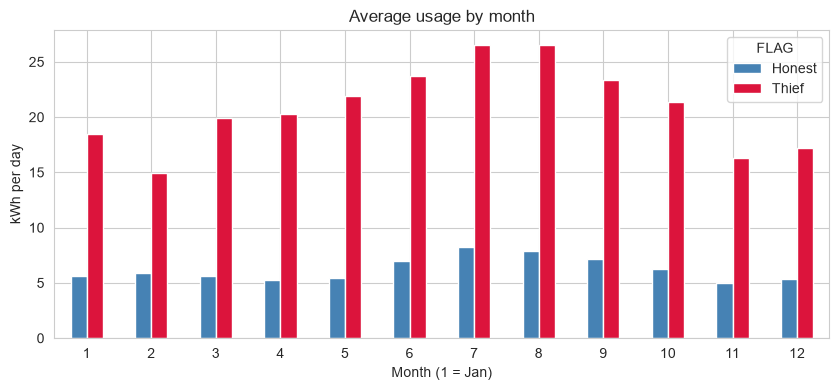

In [18]:
monthly = avg.groupby(avg.index.month).mean()
monthly.plot(kind="bar", figsize=(10, 4), color=["steelblue", "crimson"])
plt.title("Average usage by month")
plt.xlabel("Month (1 = Jan)")
plt.ylabel("kWh per day")
plt.xticks(rotation=0)
plt.savefig("../reports/figures/5_monthly_pattern.png", dpi=150, bbox_inches="tight")
plt.show()